# BaraLens: Understanding African Perspectives on Regional Integration Through Machine Learning

## 1. Dataset description

**Source:** Afrobarometer Round 10 merged dataset (38 countries, 2024/2025 fieldwork, release 25 Feb 2026).
- Data: https://www.afrobarometer.org/survey-resource/merged-round-10-data-38-countries-2025/
- Codebook: https://www.afrobarometer.org/survey-resource/merged-round-10-codebook-38-countries-2025/

Afrobarometer runs face-to-face, nationally representative surveys of adults (18+). The merged file has **50,961 respondents and 425 variables**.
I extracted the 26 columns used here from the SPSS `.sav` file into `data/afrobarometer_r10_baralens.csv`
(raw survey codes kept, so all cleaning is visible in this notebook).

## 2. Mission connection

Many young Africans only meet politics through social media and headlines. My mission is to learn how governance
and regional cooperation actually work. This project asks a narrower, measurable question:

> **How do demographic, educational and governance-related characteristics relate to people's openness to regional integration?**

The target is a **Regional Openness Index (0–1)**. The model does **not** measure leadership potential or the effect of civic education;
it only describes patterns in survey answers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

raw = pd.read_csv("data/afrobarometer_r10_baralens.csv")
print(raw.shape)

(50961, 27)


## 3. Data inspection

In [2]:
raw.head()

,RESPNO,COUNTRY,COUNTRY.BY.REGION,URBRUR,Q1,Q7A,Q22,Q65A,Q65D,Q67F,...,Q74,Q75,Q76A,Q76B,Q88D,Q88F,Q94A,Q96,Q101,withinwt_hh
0,ANG0001,2.0,3.0,2.0,21.0,4.0,9.0,0.0,0.0,9.0,...,0.0,3.0,2.0,2.0,3.0,3.0,1.0,2.0,2.0,0.742673
1,ANG0002,2.0,3.0,2.0,40.0,2.0,3.0,4.0,0.0,5.0,...,0.0,3.0,2.0,2.0,4.0,4.0,1.0,4.0,1.0,0.618894
2,ANG0003,2.0,3.0,2.0,25.0,3.0,9.0,0.0,0.0,9.0,...,0.0,9.0,9.0,9.0,5.0,1.0,0.0,5.0,1.0,0.742673
3,ANG0004,2.0,3.0,1.0,20.0,2.0,9.0,3.0,4.0,2.0,...,0.0,1.0,2.0,2.0,4.0,4.0,2.0,2.0,1.0,0.793267
4,ANG0005,2.0,3.0,1.0,18.0,2.0,2.0,3.0,4.0,9.0,...,0.0,2.0,2.0,2.0,4.0,2.0,1.0,4.0,1.0,0.495792


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50961 entries, 0 to 50960
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   RESPNO             50961 non-null  str    
 1   COUNTRY            50961 non-null  float64
 2   COUNTRY.BY.REGION  50961 non-null  float64
 3   URBRUR             50961 non-null  float64
 4   Q1                 50961 non-null  float64
 5   Q7A                50961 non-null  float64
 6   Q22                50961 non-null  float64
 7   Q65A               50961 non-null  float64
 8   Q65D               50961 non-null  float64
 9   Q67F               50961 non-null  float64
 10  Q70A               50961 non-null  float64
 11  Q70B               50961 non-null  float64
 12  Q71A               50961 non-null  float64
 13  Q73A               50961 non-null  float64
 14  Q73B               50961 non-null  float64
 15  Q73C               50961 non-null  float64
 16  Q73D               50961 non-null

In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
COUNTRY,50961.0,30.45,15.19,2.00,21.00,31.00,43.00,54.00
COUNTRY.BY.REGION,50961.0,2.31,1.27,1.00,1.00,2.00,3.00,5.00
URBRUR,50961.0,1.52,0.53,1.00,1.00,2.00,2.00,3.00
Q1,50961.0,38.66,22.40,18.00,26.00,35.00,48.00,999.00
Q7A,50961.0,1.22,1.28,0.00,0.00,1.00,2.00,9.00
Q22,50961.0,2.70,1.32,-1.00,2.00,3.00,3.00,9.00
Q65A,50961.0,2.44,1.61,0.00,1.00,3.00,4.00,9.00
Q65D,50961.0,2.00,1.88,0.00,0.00,2.00,4.00,9.00
Q67F,50961.0,5.13,2.50,1.00,4.00,4.00,9.00,9.00
Q70A,50961.0,239.92,1514.74,1.00,4.00,4.00,5.00,9994.00


Every survey answer is stored as a number code. Some codes are real answers, others mean
*refused* (8 / 98), *don't know* (9 / 99), *not applicable* (5, 7) or *not asked* (-1, 9994).
If I leave those codes in, the model would treat "don't know = 9" as a very high answer, so they must be turned into missing values first.

## 4. Missing-value analysis

In [5]:
# Which codes are real answers for each question (everything else = missing)
valid_ranges = {
    "Q1": (18, 100), "Q96": (0, 9), "Q73D": (1, 4), "Q70B": (1, 5), "Q65D": (0, 4),
    "Q94A": (0, 3), "Q74": (0, 1), "Q73A": (0, 4), "Q73B": (0, 3), "Q73C": (0, 3),
    "Q88D": (1, 5), "Q88F": (1, 5),
}

def clean_survey_data(df):
    df = df.copy()
    for col, (low, high) in valid_ranges.items():
        df[col] = df[col].where(df[col].between(low, high))
    # Q76A / Q76B: 2 = agree with statement 1, 3 = agree with statement 2. 5, 8, 9 are not usable
    for col in ["Q76A", "Q76B"]:
        df[col] = df[col].where(df[col].isin([2, 3]))
    return df

clean = clean_survey_data(raw)

missing = pd.DataFrame({
    "missing_before_cleaning": raw.isna().sum(),
    "missing_after_cleaning": clean.isna().sum(),
})
missing["pct_after"] = (missing["missing_after_cleaning"] / len(clean) * 100).round(1)
missing.sort_values("pct_after", ascending=False)

,missing_before_cleaning,missing_after_cleaning,pct_after
Q70B,0,10662,20.9
Q73D,0,6980,13.7
Q76B,0,1935,3.8
Q76A,0,1638,3.2
Q73B,0,1108,2.2
Q73A,0,1110,2.2
Q74,0,1093,2.1
Q73C,0,1082,2.1
Q88F,0,649,1.3
Q88D,0,419,0.8


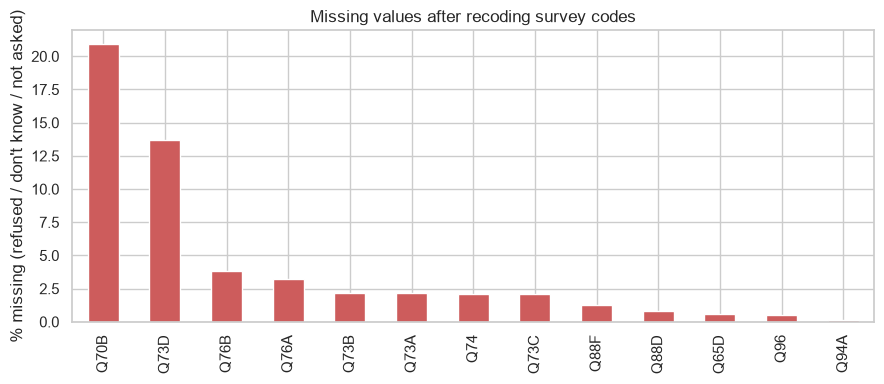

In [6]:
pct = missing["pct_after"].sort_values(ascending=False)
pct = pct[pct > 0]
plt.figure(figsize=(9, 4))
pct.plot(kind="bar", color="indianred")
plt.ylabel("% missing (refused / don't know / not asked)")
plt.title("Missing values after recoding survey codes")
plt.tight_layout()
plt.show()

The biggest gaps are in `Q70B` (African Union recognises our needs, ~21%) and `Q73D` (border ease, ~14%), mostly
"don't know / haven't heard enough". Those people genuinely have no opinion, so I don't invent one by imputing:
rows with any missing model input are dropped later. We still keep more than 35,000 rows.

## 5. Feature engineering – building the target

The questionnaire items `Q73D, Q74, Q75, Q76A, Q76B` were my starting point, but they don't measure one thing:
`Q73D` is a *perception* (how easy is it to cross borders), `Q74` is *awareness* (heard of AfCFTA, yes/no) and `Q75` is a
nominal choice. Only `Q76A/B` are attitudes. So I built a broader **Regional Openness Index** from 7 attitude items,
each rescaled to 0–1 so that 1 = most open:

| Item | Question | Recoding |
|---|---|---|
| Q73A | Migrants are good/bad for the economy | 0–4 → /4 |
| Q73B | Admit more/fewer job seekers from other countries | 0–3 → /3 |
| Q73C | Admit more/fewer refugees | 0–3 → /3 |
| Q76A | Open trade vs protect local producers | open = 1, protect = 0 |
| Q76B | Free movement in the region vs limit movement | free = 1, limit = 0 |
| Q88D | Like/dislike immigrants as neighbours | 1–5 → (x-1)/4 |
| Q88F | Like/dislike refugees as neighbours | 1–5 → (x-1)/4 |

The index is the mean of the items a person answered (needs at least 5 of 7).

In [7]:
def build_integration_index(df):
    items = pd.DataFrame({
        "Q73A": df["Q73A"] / 4,
        "Q73B": df["Q73B"] / 3,
        "Q73C": df["Q73C"] / 3,
        "Q76A": df["Q76A"].map({2: 1.0, 3: 0.0}),
        "Q76B": df["Q76B"].map({2: 1.0, 3: 0.0}),
        "Q88D": (df["Q88D"] - 1) / 4,
        "Q88F": (df["Q88F"] - 1) / 4,
    })
    answered = items.notna().sum(axis=1)
    index = items.mean(axis=1).where(answered >= 5)
    return index, items

clean["openness_index"], index_items = build_integration_index(clean)

def cronbach_alpha(items):
    items = items.dropna()
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))

print("Cronbach's alpha (7 items):", round(cronbach_alpha(index_items), 3))
print(index_items.corr().round(2))

Cronbach's alpha (7 items): 0.533
      Q73A  Q73B  Q73C  Q76A  Q76B  Q88D  Q88F
Q73A  1.00  0.28  0.13  0.08  0.09  0.18  0.12
Q73B  0.28  1.00  0.39  0.03  0.04  0.12  0.10
Q73C  0.13  0.39  1.00  0.05  0.07  0.12  0.21
Q76A  0.08  0.03  0.05  1.00  0.42  0.05  0.07
Q76B  0.09  0.04  0.07  0.42  1.00  0.06  0.07
Q88D  0.18  0.12  0.12  0.05  0.06  1.00  0.52
Q88F  0.12  0.10  0.21  0.07  0.07  0.52  1.00


**Honest note on the index:** Cronbach's alpha is about 0.53, below the usual 0.6–0.7 for a single scale. The correlation table shows
three groups of items (views on migrants, trade/free-movement policy, migrants as neighbours). So I treat this as a
**formative index** – it combines the three parts of the AU / AfCFTA integration agenda (people, trade, movement) –
and not as a measure of one hidden trait. With ~220 distinct values it works as a continuous target.

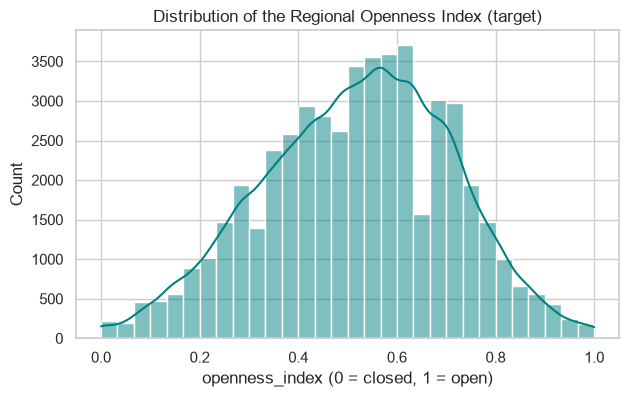

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(clean["openness_index"].dropna(), bins=30, kde=True, color="teal")
plt.title("Distribution of the Regional Openness Index (target)")
plt.xlabel("openness_index (0 = closed, 1 = open)")
plt.show()

## 6. Feature selection

I picked 10 predictors that are about **demographics, education and governance**, which is the scope of the mission:

| Feature | Source | Type |
|---|---|---|
| age | Q1 | numeric |
| education | Q96 (0 = none … 9 = post-graduate) | numeric (ordinal) |
| border_ease | Q73D (1 = very difficult … 4 = very easy) | numeric (ordinal) |
| au_recognition | Q70B AU recognises our needs (1–5) | numeric (ordinal) |
| social_media_news | Q65D (0 = never … 4 = every day) | numeric (ordinal) |
| gender | Q101 | categorical |
| area | URBRUR | categorical |
| country | COUNTRY (38 countries) | categorical |
| employment | Q94A | categorical |
| afcfta_aware | Q74 heard of AfCFTA | categorical |

Not used: items that are *part of the target* (Q73A–C, Q76A/B, Q88D/F – using them would leak the answer),
IDs (RESPNO), weights, and `Q75` (it is itself a trade-openness answer, too close to the target).

In [9]:
country_names = {
    2: "Angola", 3: "Benin", 4: "Botswana", 7: "Cabo Verde", 8: "Cameroon", 10: "Chad", 11: "Comoros",
    13: "Congo-Brazzaville", 14: "Cote d'Ivoire", 19: "Eswatini", 21: "Gabon", 22: "Gambia", 23: "Ghana",
    24: "Guinea", 25: "Guinea-Bissau", 26: "Kenya", 27: "Lesotho", 28: "Liberia", 30: "Madagascar",
    31: "Malawi", 32: "Mali", 33: "Mauritania", 34: "Mauritius", 35: "Morocco", 36: "Mozambique",
    37: "Namibia", 39: "Nigeria", 41: "Sao Tome and Principe", 42: "Senegal", 43: "Seychelles",
    44: "Sierra Leone", 46: "South Africa", 49: "Tanzania", 50: "Togo", 51: "Tunisia", 52: "Uganda",
    53: "Zambia", 54: "Zimbabwe",
}

def make_model_table(df):
    table = pd.DataFrame({
        "age": df["Q1"],
        "education": df["Q96"],
        "border_ease": df["Q73D"],
        "au_recognition": df["Q70B"],
        "social_media_news": df["Q65D"],
        "gender": df["Q101"].map({1: "Man", 2: "Woman"}),
        "area": df["URBRUR"].map({1: "Urban", 2: "Rural", 3: "Peri-Urban"}),
        "country": df["COUNTRY"].map(country_names),
        "employment": df["Q94A"].map({0: "Not working, not looking", 1: "Not working, looking",
                                      2: "Part time", 3: "Full time"}),
        "afcfta_aware": df["Q74"].map({0: "No", 1: "Yes"}),
        "openness_index": df["openness_index"],
    })
    return table.dropna()

data = make_model_table(clean)
NUMERIC_FEATURES = ["age", "education", "border_ease", "au_recognition", "social_media_news"]
CATEGORICAL_FEATURES = ["gender", "area", "country", "employment", "afcfta_aware"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "openness_index"

print("Rows used:", len(data), "| predictors:", len(FEATURES))
data.head()

Rows used: 35988 | predictors: 10


,age,education,border_ease,au_recognition,social_media_news,gender,area,country,employment,afcfta_aware,openness_index
1,40.0,4.0,4.0,4.0,0.0,Man,Rural,Angola,"Not working, looking",No,0.630952
3,20.0,2.0,2.0,1.0,4.0,Man,Urban,Angola,Part time,No,0.595238
4,18.0,4.0,1.0,4.0,4.0,Man,Urban,Angola,"Not working, looking",No,0.678571
8,56.0,4.0,1.0,4.0,3.0,Woman,Urban,Angola,"Not working, not looking",No,0.333333
9,48.0,4.0,2.0,3.0,2.0,Woman,Urban,Angola,Full time,Yes,0.333333


## 7. Visualisations

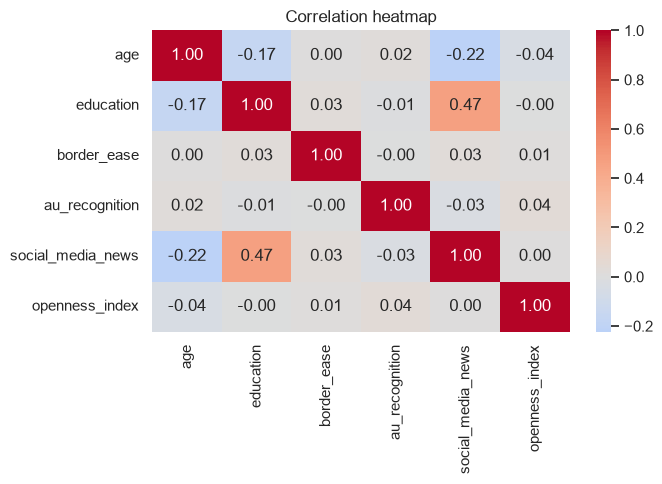

In [10]:
# Correlation heatmap (numeric features + target)
plt.figure(figsize=(7, 5))
sns.heatmap(data[NUMERIC_FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

The numeric features each have only weak linear correlation with the index (all small in size). This already tells me a
linear model will not explain much of the variance – attitudes depend on many things not in a survey.

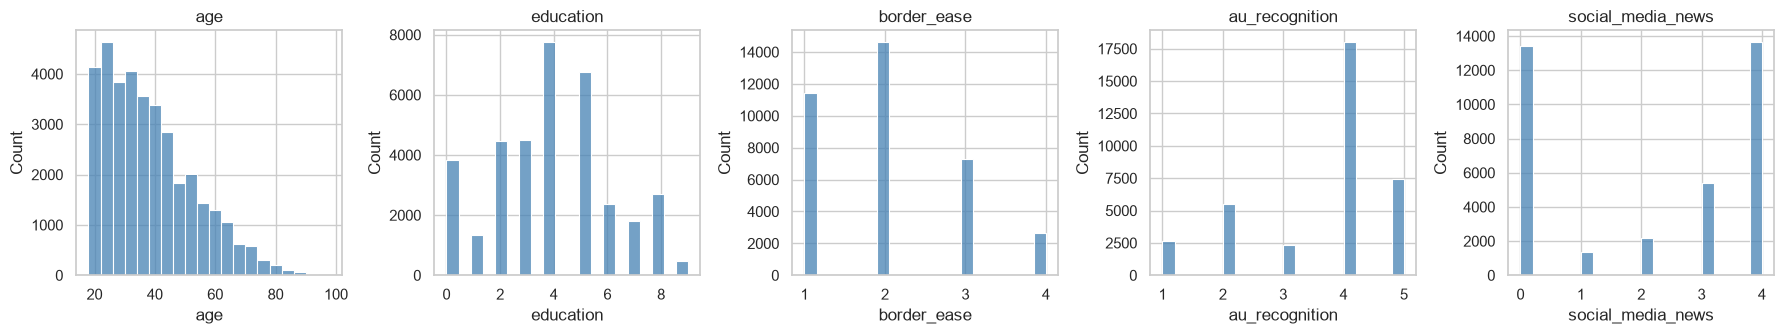

In [11]:
# Distributions of numeric features
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.histplot(data[col], ax=ax, bins=20, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

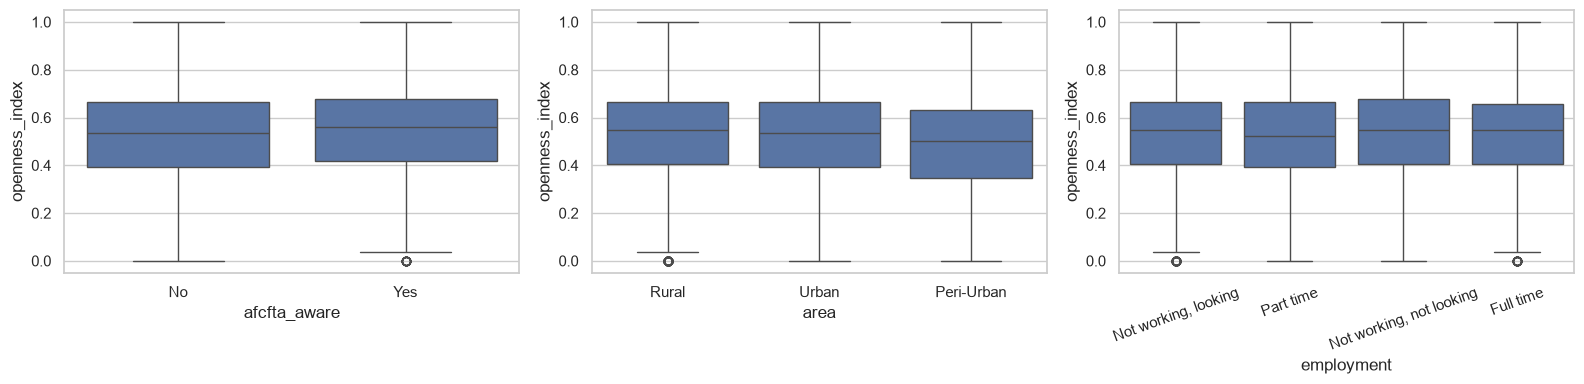

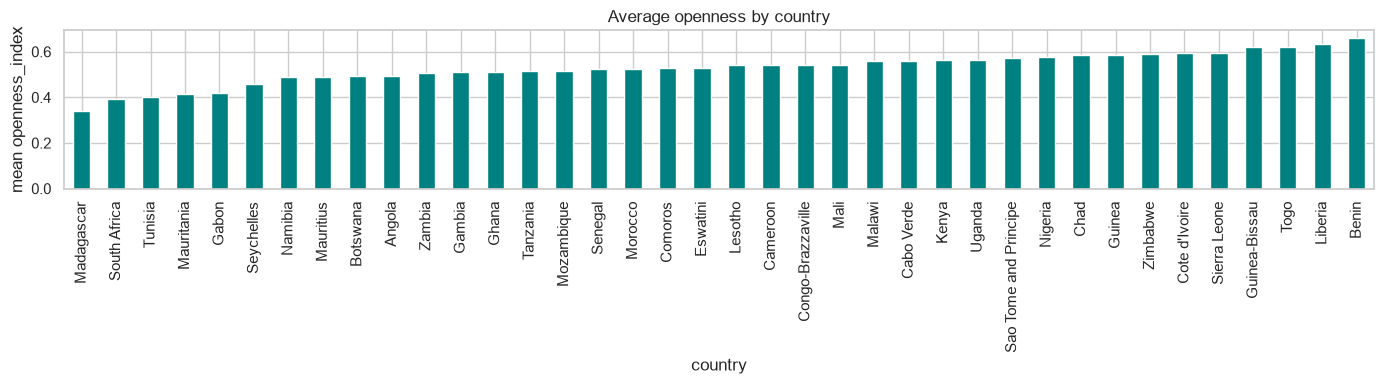

In [12]:
# Boxplots: does the index differ across categories?
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=data, x="afcfta_aware", y=TARGET, ax=axes[0])
sns.boxplot(data=data, x="area", y=TARGET, ax=axes[1])
sns.boxplot(data=data, x="employment", y=TARGET, ax=axes[2])
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Country has the biggest spread, so show mean index per country
plt.figure(figsize=(14, 4))
data.groupby("country")[TARGET].mean().sort_values().plot(kind="bar", color="teal")
plt.ylabel("mean openness_index")
plt.title("Average openness by country")
plt.tight_layout()
plt.show()

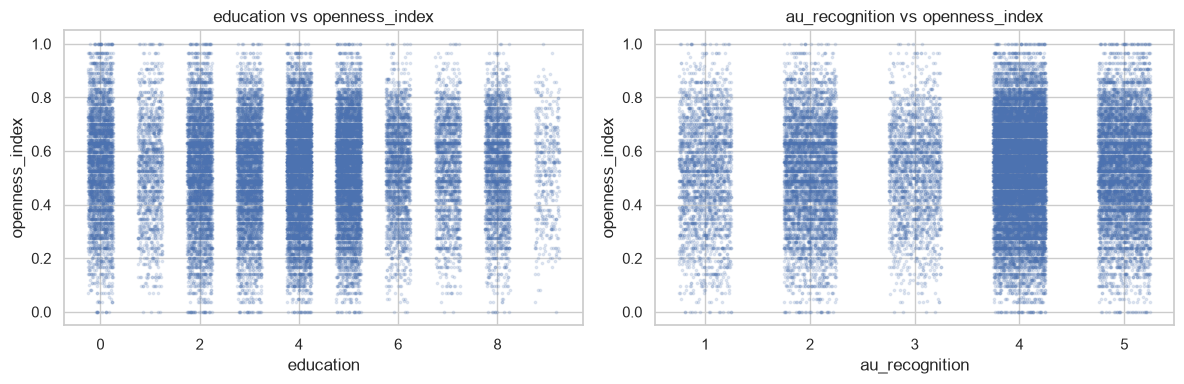

In [13]:
# Scatter of two features against the target (jitter because answers are whole numbers)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["education", "au_recognition"]):
    jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.25, 0.25, len(data))
    ax.scatter(data[col] + jitter, data[TARGET], s=3, alpha=0.15)
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.set_title(f"{col} vs openness_index")
plt.tight_layout()
plt.show()

## 8. Train / test split

One fixed 80/20 split (`random_state=42`) is used for **all** models so the comparison is fair.

In [14]:
X = data[FEATURES]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train:", X_train.shape, "test:", X_test.shape)

train: (28790, 10) test: (7198, 10)


## 9. Categorical encoding + standardisation (no data leakage)

- Numeric features → `StandardScaler`
- Categorical features → `OneHotEncoder(handle_unknown="ignore")`

Both live inside a `Pipeline`, so `.fit()` only ever sees the **training** rows. The test set is transformed with the
means/stds/categories learned from training data. The same pipeline is saved with the model, so the API does the exact same preprocessing.

In [15]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])

def make_pipeline(model):
    return Pipeline([("preprocess", make_preprocessor()), ("model", model)])

# quick look at the encoded training matrix
encoded = make_preprocessor().fit(X_train)
print("Columns after encoding:", len(encoded.get_feature_names_out()))

Columns after encoding: 54


## 10. Before training: scatter of the data

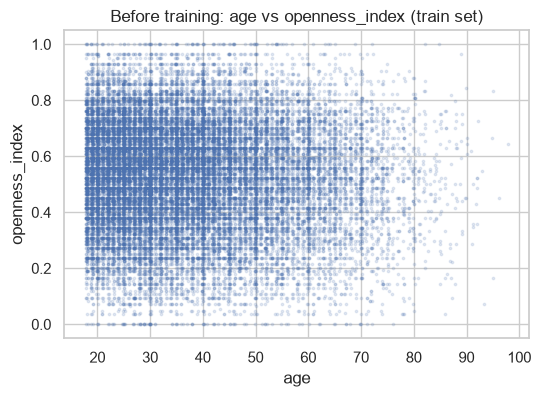

In [16]:
# "Before" view: the raw relationship between the strongest numeric feature and the target, no model yet
best_num = data[NUMERIC_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).abs().idxmax()
plt.figure(figsize=(6, 4))
jitter = np.random.default_rng(1).uniform(-0.25, 0.25, len(X_train))
plt.scatter(X_train[best_num] + jitter, y_train, s=3, alpha=0.15)
plt.xlabel(best_num)
plt.ylabel(TARGET)
plt.title(f"Before training: {best_num} vs openness_index (train set)")
plt.show()

## 11. Models

Four models on the same split:
1. `LinearRegression` (closed-form least squares)
2. `SGDRegressor` (linear model trained with gradient descent)
3. `DecisionTreeRegressor`
4. `RandomForestRegressor`

### 11a. SGDRegressor hyperparameter experiments

In [17]:
sgd_results = []
for eta0 in [0.0001, 0.001, 0.01, 0.1]:
    for alpha in [0.0001, 0.001, 0.01]:
        pipe = make_pipeline(SGDRegressor(learning_rate="invscaling", eta0=eta0, alpha=alpha, penalty="l2",
                                          max_iter=1000, tol=1e-4, random_state=RANDOM_STATE))
        pipe.fit(X_train, y_train)
        sgd_results.append({
            "eta0": eta0, "alpha": alpha,
            "train_mse": mean_squared_error(y_train, pipe.predict(X_train)),
            "test_mse": mean_squared_error(y_test, pipe.predict(X_test)),
        })

sgd_table = pd.DataFrame(sgd_results).sort_values("test_mse")
sgd_table.round(5)

,eta0,alpha,train_mse,test_mse
6,0.0100,0.0001,0.03055,0.02982
7,0.0100,0.0010,0.03057,0.02984
8,0.0100,0.0100,0.03098,0.03024
11,0.1000,0.0100,0.03118,0.03040
9,0.1000,0.0001,0.03125,0.03068
10,0.1000,0.0010,0.03127,0.03069
3,0.0010,0.0001,0.03233,0.03162
4,0.0010,0.0010,0.03235,0.03164
5,0.0010,0.0100,0.03255,0.03184
0,0.0001,0.0001,0.03692,0.03593


In [18]:
best_sgd_params = sgd_table.iloc[0]
print("Best SGD settings:", dict(eta0=best_sgd_params.eta0, alpha=best_sgd_params.alpha))

Best SGD settings: {'eta0': np.float64(0.01), 'alpha': np.float64(0.0001)}


### 11b. SGD loss curves (train vs test MSE per epoch)

To see the loss per epoch I train SGD one pass at a time with `partial_fit`. The preprocessing is fitted on the
training data once, then reused for the test data.

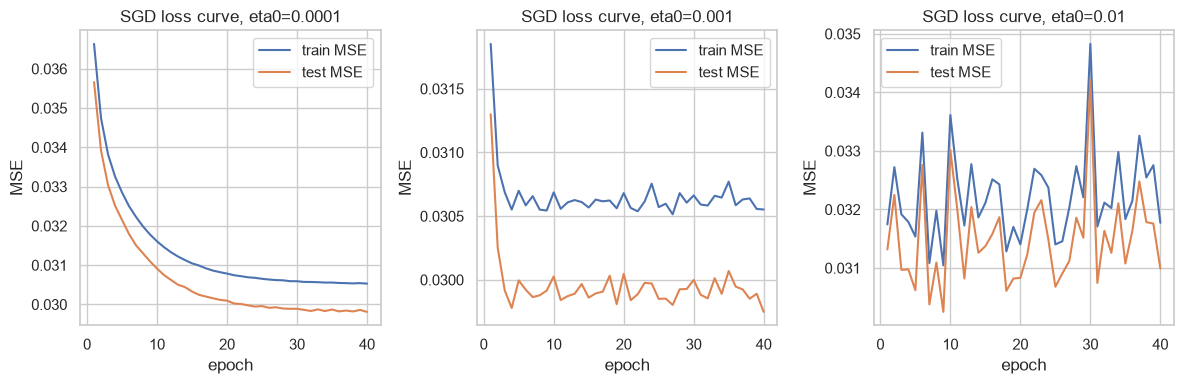

In [19]:
prep = make_preprocessor().fit(X_train)
X_train_enc = prep.transform(X_train)
X_test_enc = prep.transform(X_test)

def sgd_loss_curve(eta0, alpha, epochs=40):
    sgd = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, random_state=RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    train_curve, test_curve = [], []
    for epoch in range(epochs):
        order = rng.permutation(X_train_enc.shape[0])  # shuffle each epoch like normal SGD
        sgd.partial_fit(X_train_enc[order], y_train.values[order])
        train_curve.append(mean_squared_error(y_train, sgd.predict(X_train_enc)))
        test_curve.append(mean_squared_error(y_test, sgd.predict(X_test_enc)))
    return train_curve, test_curve

plt.figure(figsize=(12, 4))
for i, eta0 in enumerate([0.0001, 0.001, 0.01]):
    train_curve, test_curve = sgd_loss_curve(eta0, best_sgd_params.alpha)
    plt.subplot(1, 3, i + 1)
    plt.plot(range(1, 41), train_curve, label="train MSE")
    plt.plot(range(1, 41), test_curve, label="test MSE")
    plt.title(f"SGD loss curve, eta0={eta0}")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.legend()
plt.tight_layout()
plt.show()

In the experiment table, `eta0=0.0001` is far too slow: after training, its test MSE (~0.036) is still worse than the mean baseline. `eta0=0.01` gave the lowest test MSE (~0.0298), matching closed-form LinearRegression. Changing `alpha` (L2 penalty) barely mattered. Train and test curves stay close together, so the linear model is **not overfitting** – its limit is underfitting (weak linear signal).

### 11c. Train all four models

In [20]:
# Decision tree: pick max_depth with 5-fold CV on the TRAINING set only (the test set is not used for tuning)
tree_search = GridSearchCV(
    make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"model__max_depth": [4, 6, 8, 10, 12], "model__min_samples_leaf": [20, 50]},
    scoring="neg_mean_squared_error", cv=5, n_jobs=-1,
)
tree_search.fit(X_train, y_train)
print("Decision tree best params:", tree_search.best_params_)

models = {
    "LinearRegression": make_pipeline(LinearRegression()),
    "SGDRegressor": make_pipeline(SGDRegressor(learning_rate="invscaling", eta0=best_sgd_params.eta0,
                                               alpha=best_sgd_params.alpha, max_iter=1000, tol=1e-4,
                                               random_state=RANDOM_STATE)),
    "DecisionTree": tree_search.best_estimator_,
    "RandomForest": make_pipeline(RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=10,
                                                        n_jobs=-1, random_state=RANDOM_STATE)),
}

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    results.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, train_pred),
        "test_mse": mean_squared_error(y_test, test_pred),
        "test_r2": r2_score(y_test, test_pred),
    })

baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
results = pd.DataFrame(results).sort_values("test_mse").reset_index(drop=True)
print("Baseline (always predict the training mean) test MSE:", round(baseline_mse, 5))
results.round(5)

Decision tree best params: {'model__max_depth': 12, 'model__min_samples_leaf': 50}


Baseline (always predict the training mean) test MSE: 0.03514


,model,train_mse,test_mse,test_r2
0,LinearRegression,0.03049,0.02978,0.15222
1,SGDRegressor,0.03055,0.02982,0.15104
2,RandomForest,0.02916,0.03032,0.13674
3,DecisionTree,0.03088,0.03082,0.12263


## 12. Train / test MSE comparison

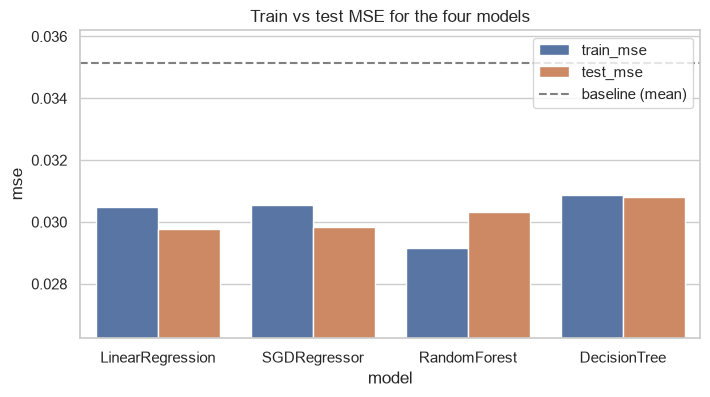

In [21]:
plot_df = results.melt(id_vars="model", value_vars=["train_mse", "test_mse"], var_name="split", value_name="mse")
plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x="model", y="mse", hue="split")
plt.axhline(baseline_mse, color="grey", linestyle="--", label="baseline (mean)")
plt.ylim(plot_df["mse"].min() * 0.9, baseline_mse * 1.03)
plt.title("Train vs test MSE for the four models")
plt.legend()
plt.show()

## 13. After training: fitted linear regression line

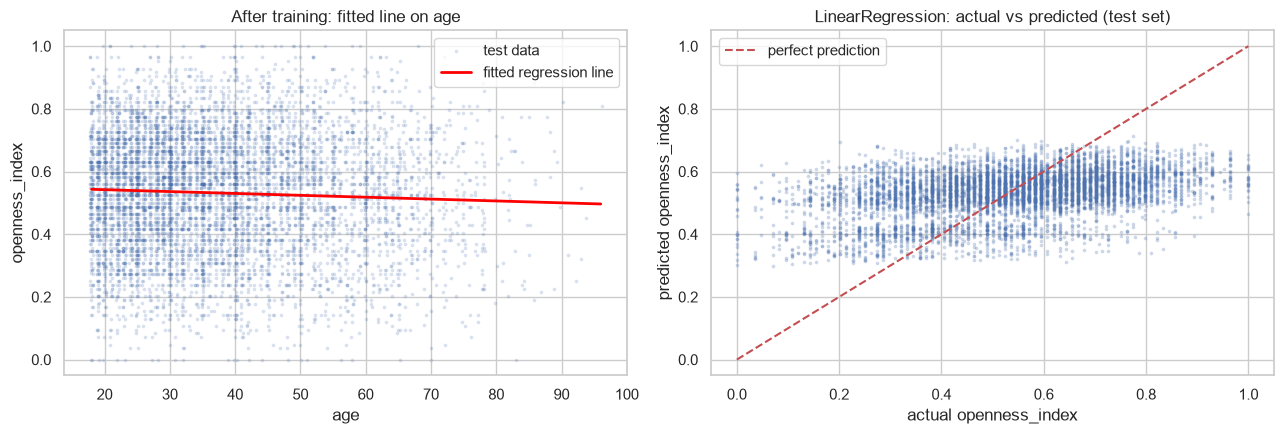

In [22]:
lin = models["LinearRegression"]
lin_test_pred = lin.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Fitted line on the strongest numeric feature: what the linear model predicts as that feature changes
axes[0].scatter(X_test[best_num] + np.random.default_rng(2).uniform(-0.25, 0.25, len(X_test)), y_test, s=3, alpha=0.15, label="test data")
slope, intercept = np.polyfit(X_test[best_num], lin_test_pred, 1)
xs = np.linspace(X_test[best_num].min(), X_test[best_num].max(), 50)
axes[0].plot(xs, slope * xs + intercept, color="red", linewidth=2, label="fitted regression line")
axes[0].set_xlabel(best_num)
axes[0].set_ylabel(TARGET)
axes[0].set_title(f"After training: fitted line on {best_num}")
axes[0].legend()

# Actual vs predicted for all features together
axes[1].scatter(y_test, lin_test_pred, s=3, alpha=0.2)
line = np.linspace(0, 1, 10)
axes[1].plot(line, line, "r--", label="perfect prediction")
axes[1].set_xlabel("actual openness_index")
axes[1].set_ylabel("predicted openness_index")
axes[1].set_title("LinearRegression: actual vs predicted (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 14. Best model selection

In [23]:
best_name = results.iloc[0]["model"]
best_model = models[best_name]
print("Best model by lowest test MSE:", best_name)
print(results.iloc[0][["train_mse", "test_mse", "test_r2"]].astype(float).round(5).to_dict())

Best model by lowest test MSE: LinearRegression
{'train_mse': 0.03049, 'test_mse': 0.02978, 'test_r2': 0.15222}


**Selection rule:** the model with the **lowest test MSE** on the shared held-out test set wins, because test MSE measures error on people the model has never seen.

**Result:** `LinearRegression` has the lowest test MSE (0.02978, R² ≈ 0.15), just ahead of SGDRegressor (0.02982). RandomForest has the lowest *train* MSE (0.0292) but a higher test MSE (0.0303), so it is slightly overfitting; the tuned Decision Tree is worst (0.0308). Most of the signal comes from additive differences between countries plus small effects of education, media use and views on the AU, which a linear model captures well.

All models beat the mean baseline (0.0351), but only modestly: attitudes toward integration depend on many things that are not in these 10 survey answers.

## 15. Save the best model (with its preprocessing)

In [24]:
bundle = {
    "pipeline": best_model,          # preprocessing + model in one object
    "model_name": best_name,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target": TARGET,
    "test_mse": float(results.iloc[0]["test_mse"]),
}
joblib.dump(bundle, "../API/best_model.pkl", compress=3)

# Cleaned training table, used by the API's /retrain endpoint and for demo uploads
data.to_csv("../API/training_data.csv", index=False)
data.sample(500, random_state=RANDOM_STATE).to_csv("../API/retrain_sample.csv", index=False)
print("saved")

saved


## 16. Predict on one row of the test set

In [25]:
loaded = joblib.load("../API/best_model.pkl")
one_row = X_test.iloc[[0]]
print(one_row.T)
print("Predicted openness_index:", round(float(loaded["pipeline"].predict(one_row)[0]), 4))
print("Actual openness_index:   ", round(float(y_test.iloc[0]), 4))

                                   7038
age                                24.0
education                           6.0
border_ease                         1.0
au_recognition                      2.0
social_media_news                   4.0
gender                              Man
area                              Rural
country                   Cote d'Ivoire
employment         Not working, looking
afcfta_aware                         No
Predicted openness_index: 0.5896
Actual openness_index:    0.6667


## Conclusion

- 35k+ Afrobarometer respondents, 10 predictors (5 numeric, 5 categorical), formative 0–1 openness index as target.
- Preprocessing is fitted on training data only and saved inside the model pipeline.
- The best model (lowest test MSE) is saved to `API/best_model.pkl` and is used by the FastAPI `/predict` endpoint.
- **Limitation:** the models explain only a small part of the variation. Possible improvements: add more governance and
  information variables (trust in institutions, news use), use survey weights, or model each part of the index separately.